# 從零訓練手繪辨識模型

**Sell Anything 的第一個模型**：玩家在遊戲裡用滑鼠畫一個東西，這個模型要猜出畫的是什麼。

這本筆記本是**教學模式**：我們不會一開始就端出最好的模型，而是從最笨的方法開始，
**一次只改一件事**，每一關都量出 loss 和準確率，親眼看它一步一步變好。

| 關卡 | 改了什麼 | 想學會的觀念 |
|---|---|---|
| 第 0 關 | 什麼都不學，亂猜 | 基準線：「多爛才叫爛」 |
| 第 1 關 | 線性模型（先故意做錯） | 正規化為什麼重要；模型其實在比對「範本」 |
| 第 2 關 | 加一層隱藏層（MLP） | 隱藏層、ReLU |
| 第 3 關 | 卷積神經網路（CNN） | 卷積 = 在圖上滑動的小印章 |
| 第 4 關 | 更深的 CNN + BatchNorm | 讓深的網路也好訓練 |
| 第 5 關 | Dropout + 資料增強 | 過擬合是什麼、怎麼對抗 |
| 第 6 關 | 學習率排程 | 先大步走、再小步走 |
| 期末考 | 用測試集打分數 | 為什麼測試集只能用一次 |

**怎麼用**：從上到下一格一格執行（選中一格按 `Shift + Enter`）。
全部跑完在 Apple M 系列的 Mac 上大約 6 分鐘（第一次執行還要下載約 94 MB 的資料）。
講解裡寫的數字都是實際跑出來的；你重跑時可能會差一點點，但趨勢會一樣。

> 每一格程式碼的註解都寫得很細。看不懂的時候，先看那一格上方的說明，再看程式碼裡的註解。

## 0. 準備工作：匯入工具、選擇用哪個晶片計算

我們會用到：

| 套件 | 用途 |
|---|---|
| `torch`（PyTorch） | 建模型、訓練模型 |
| `numpy` | 處理一般的數字陣列 |
| `matplotlib` | 畫圖 |

**裝置（device）** 是「讓誰來算」：
- `cuda`：NVIDIA 顯示卡
- `mps`：Apple M 系列晶片的 GPU（你的 Mac 是這個）
- `cpu`：一般處理器，最慢但哪裡都能跑

**隨機種子（seed）**：訓練時有很多地方會「隨機」，例如權重的初始值、資料的順序。
固定種子，每次重跑的結果就會幾乎一樣，比較好對照講解裡的數字。

In [1]:
import math
import time
import urllib.parse
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# --- 選擇運算裝置：有 GPU 就用 GPU，沒有就用 CPU ---
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("運算裝置：", device)

# --- 固定隨機種子，讓結果可以重現 ---
SEED = 0
torch.manual_seed(SEED)
rng = np.random.default_rng(SEED)  # numpy 用的隨機產生器

# --- 讓 matplotlib 可以顯示中文（依序嘗試 Mac / Windows 常見的中文字型）---
plt.rcParams["font.sans-serif"] = ["Heiti TC", "PingFang HK", "Microsoft JhengHei",
                                   "Arial Unicode MS", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False  # 讓負號正常顯示

# 記下開始時間，最後可以看整本跑了多久
NOTEBOOK_START = time.time()

運算裝置： mps


## 1. 下載資料：Google 的 Quick, Draw!

[Quick, Draw!](https://github.com/googlecreativelab/quickdraw-dataset) 是 Google 做的小遊戲：
請玩家在 20 秒內畫出指定的東西。全世界的玩家一共留下了 **5,000 萬張**塗鴉，分成 345 類。

Google 也提供了整理好的版本：每張圖都縮成 **28 × 28 的灰階圖**，
每個類別存成一個 `.npy` 檔（numpy 的陣列格式）。

### 一個省流量的小技巧

一個類別的檔案大約 100 MB 以上（例如 `apple.npy` 有 144,722 張圖、113 MB）。
我們只需要每類前 12,000 張，所以**只下載檔案的前面一小段**就好。

這就像去圖書館影印：書有 500 頁，你只需要前 30 頁，就只影印前 30 頁。
HTTP 有一個叫 **Range** 的功能，可以跟伺服器說「我只要第 0 到第 N 個位元組」。

`.npy` 檔的結構很簡單：

```
[ 檔頭 80 位元組 ][ 第 1 張圖 784 位元組 ][ 第 2 張圖 784 位元組 ] ...
```

每張圖是 28 × 28 = 784 個像素，每個像素用 1 個位元組（0–255）存。
所以「前 12,000 張」= 80 + 12,000 × 784 位元組，大約 9.4 MB。

### 我們選的 10 個類別

先挑 10 個 Sell Anything 裡「可以賣」的東西。其中故意放了**長得有點像的**（貓和狗），
看模型會不會搞混。之後要擴充到 345 類，只要改這個清單。

In [2]:
# 這 10 類都來自 ml/data/items.tsv 裡標記為 buy（可以賣）的物品
CATEGORIES = ["apple", "banana", "bicycle", "cat", "dog",
              "cell phone", "chair", "guitar", "umbrella", "wristwatch"]
CATEGORIES_ZH = ["蘋果", "香蕉", "腳踏車", "貓", "狗",
                 "手機", "椅子", "吉他", "雨傘", "手錶"]

PER_CLASS = 12_000            # 每類取幾張
IMAGE_BYTES = 28 * 28         # 一張圖 784 個位元組
DATA_DIR = Path("../data/raw/quickdraw")   # 這個資料夾已經在 .gitignore 裡，不會被 commit
DATA_DIR.mkdir(parents=True, exist_ok=True)
BASE_URL = "https://storage.googleapis.com/quickdraw_dataset/full/numpy_bitmap/"


def download_first_n(category, n):
    '''只下載某個類別的前 n 張圖，回傳形狀 (n, 784) 的 uint8 陣列。'''
    cache = DATA_DIR / f"{category.replace(' ', '_')}_{n}.npy"
    if cache.exists():                       # 下載過就直接讀，不重複下載
        return np.load(cache)

    url = BASE_URL + urllib.parse.quote(category) + ".npy"   # 空白要轉成 %20
    # 先多抓一點點，確保檔頭一定在裡面；檔頭長度寫在第 8–9 個位元組
    want = 128 + n * IMAGE_BYTES
    request = urllib.request.Request(url, headers={"Range": f"bytes=0-{want - 1}"})
    with urllib.request.urlopen(request) as response:
        raw = response.read()

    header_len = int.from_bytes(raw[8:10], "little")   # numpy 格式規定的位置
    data_start = 10 + header_len                         # 真正的像素從這裡開始
    pixels = np.frombuffer(raw, dtype=np.uint8, offset=data_start, count=n * IMAGE_BYTES)
    images = pixels.reshape(n, IMAGE_BYTES)              # 攤開成「一列一張圖」
    np.save(cache, images)
    return images


images_per_class = []
for name in CATEGORIES:
    imgs = download_first_n(name, PER_CLASS)
    images_per_class.append(imgs)
    print(f"{name:>11s}: {imgs.shape[0]:,} 張，每張 {imgs.shape[1]} 個像素")

      apple: 12,000 張，每張 784 個像素
     banana: 12,000 張，每張 784 個像素
    bicycle: 12,000 張，每張 784 個像素
        cat: 12,000 張，每張 784 個像素
        dog: 12,000 張，每張 784 個像素
 cell phone: 12,000 張，每張 784 個像素
      chair: 12,000 張，每張 784 個像素
     guitar: 12,000 張，每張 784 個像素
   umbrella: 12,000 張，每張 784 個像素
 wristwatch: 12,000 張，每張 784 個像素


## 2. 先看看資料長什麼樣子

**動手訓練之前，一定要先看資料。** 這是做機器學習最重要的習慣：
很多 bug 不是模型的問題，而是資料本身就怪怪的（例如圖是倒的、顏色是反的）。

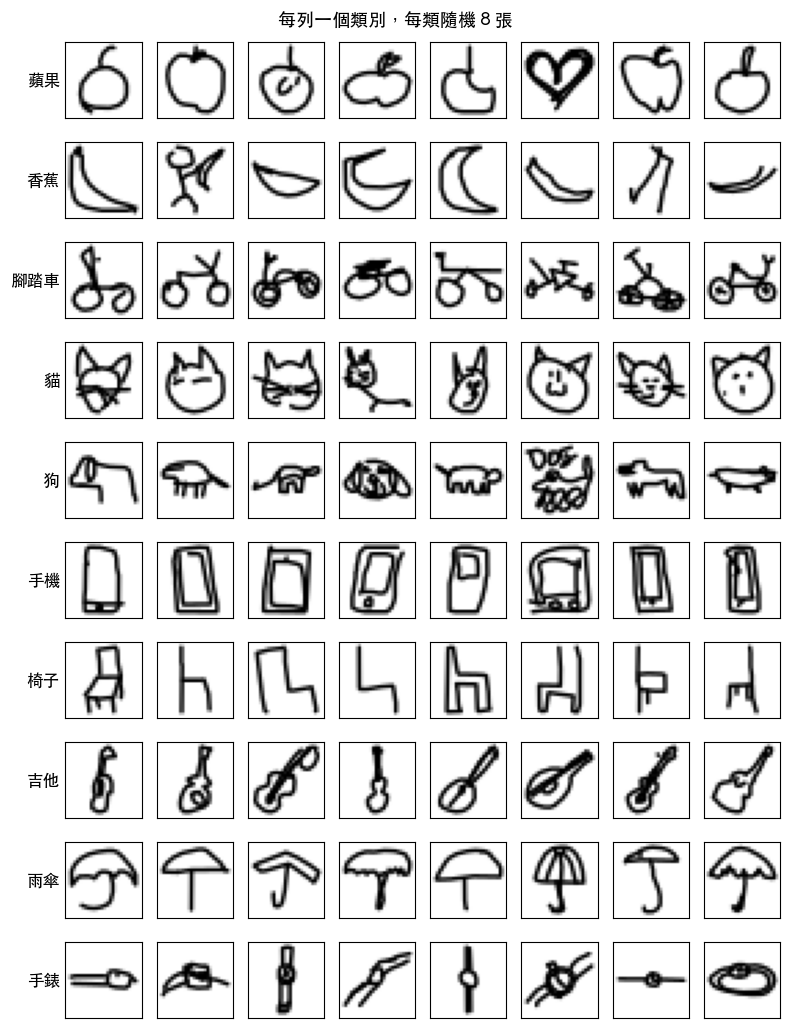

In [3]:
# 每個類別隨便挑 8 張畫出來：一列是一個類別
fig, axes = plt.subplots(len(CATEGORIES), 8, figsize=(8, 10.5))
for row, (imgs, zh) in enumerate(zip(images_per_class, CATEGORIES_ZH)):
    picks = rng.choice(len(imgs), size=8, replace=False)   # 隨機挑 8 張
    for col, idx in enumerate(picks):
        ax = axes[row, col]
        ax.imshow(imgs[idx].reshape(28, 28), cmap="gray_r")  # gray_r：0 是白、255 是黑
        ax.set_xticks([])
        ax.set_yticks([])
    axes[row, 0].set_ylabel(zh, rotation=0, ha="right", va="center", fontsize=12)
fig.suptitle("每列一個類別，每類隨機 8 張", fontsize=13)
plt.tight_layout()
plt.show()

可以看到：
- **同一類的畫法差很多**：有人畫整隻貓，有人只畫貓臉；腳踏車有側面的、也有只畫兩個輪子的。
- **有些圖根本畫錯了**：上面「蘋果」那列有一顆愛心，「香蕉」那列有一個火柴人，「狗」那列有人直接寫了 DOG 這個字。
  這些「髒資料」是真實世界的一部分，模型也得學著面對。之後看模型猜錯的圖時，記得想想這件事。

### 把一張圖放大，看它其實只是一堆數字

對電腦來說，一張圖就是 28 × 28 = 784 個數字。**0 代表空白，255 代表筆畫最濃的地方。**

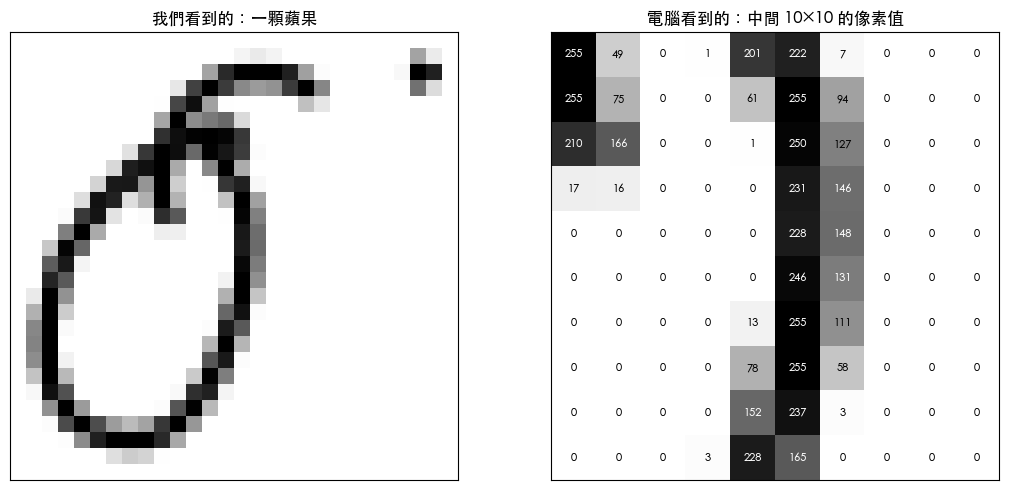

像素最小值： 0   最大值： 255   資料型別： uint8
784 個像素裡，非 0 的有 187 個


In [4]:
sample = images_per_class[0][0].reshape(28, 28)   # 第一類（蘋果）的第一張

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
ax1.imshow(sample, cmap="gray_r")
ax1.set_title("我們看到的：一顆蘋果")

# 右邊：只放大中間 10×10 的區域，把每個像素的數值直接寫上去
crop = sample[9:19, 9:19]
ax2.imshow(crop, cmap="gray_r")
for r in range(crop.shape[0]):
    for c in range(crop.shape[1]):
        v = crop[r, c]
        ax2.text(c, r, str(v), ha="center", va="center", fontsize=8,
                 color="white" if v > 128 else "black")
ax2.set_title("電腦看到的：中間 10×10 的像素值")
for ax in (ax1, ax2):
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

print("像素最小值：", sample.min(), "  最大值：", sample.max(), "  資料型別：", sample.dtype)
print("784 個像素裡，非 0 的有", (sample > 0).sum(), "個")

**重點**：像素值的範圍是 **0 到 255**，而且大部分是 0（空白）。
這個「0 到 255」等一下會害我們第一次訓練失敗，先記住它。

## 3. 把資料切成三份：訓練、驗證、測試

用考試來比喻：

| 資料 | 比喻 | 用途 | 每類張數 |
|---|---|---|---|
| 訓練集 train | 課本習題 | 模型用來學習（調整權重） | 10,000 |
| 驗證集 val | 模擬考 | 我們用來比較哪個方法比較好 | 1,000 |
| 測試集 test | 正式考試 | **最後只考一次**，回報真正的實力 | 1,000 |

**為什麼要分三份？** 如果拿課本習題來考試，學生只要背答案就能考滿分，但那不代表他真的會。
模型也一樣，**一定要用沒看過的資料來打分數**。

**為什麼不能常常看測試集？** 如果我們每改一次就去看測試成績，再依成績調整，
等於偷偷「針對考卷準備」，最後的分數就會灌水。所以這本筆記本裡，
**前面全部只看驗證集，測試集留到最後一節才打開。**

In [5]:
N_TRAIN, N_VAL, N_TEST = 10_000, 1_000, 1_000

splits = {"train": ([], []), "val": ([], []), "test": ([], [])}
for label, imgs in enumerate(images_per_class):
    order = rng.permutation(len(imgs))           # 先把這一類打亂，避免前後順序有偏差
    imgs = imgs[order]
    parts = {"train": imgs[:N_TRAIN],
             "val":   imgs[N_TRAIN:N_TRAIN + N_VAL],
             "test":  imgs[N_TRAIN + N_VAL:N_TRAIN + N_VAL + N_TEST]}
    for split, part in parts.items():
        splits[split][0].append(part)
        splits[split][1].append(np.full(len(part), label))   # 這些圖的答案都是 label


def to_tensors(split):
    '''把某一份資料合併成 PyTorch 張量：影像 (N, 1, 28, 28)、答案 (N,)'''
    x = np.concatenate(splits[split][0]).reshape(-1, 1, 28, 28)   # 1 = 灰階只有 1 個通道
    y = np.concatenate(splits[split][1])
    return torch.from_numpy(x), torch.from_numpy(y).long()


x_train, y_train = to_tensors("train")
x_val, y_val = to_tensors("val")
x_test, y_test = to_tensors("test")

for name, x, y in [("訓練", x_train, y_train), ("驗證", x_val, y_val), ("測試", x_test, y_test)]:
    print(f"{name}集：影像 {tuple(x.shape)}  答案 {tuple(y.shape)}  "
          f"每類張數 {torch.bincount(y).tolist()}")

訓練集：影像 (100000, 1, 28, 28)  答案 (100000,)  每類張數 [10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000, 10000]
驗證集：影像 (10000, 1, 28, 28)  答案 (10000,)  每類張數 [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]
測試集：影像 (10000, 1, 28, 28)  答案 (10000,)  每類張數 [1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000, 1000]


形狀 `(100000, 1, 28, 28)` 要從右往左讀：
**28 × 28 的圖**、**1 個顏色通道**（灰階；彩色照片會是 3）、**一共 100,000 張**。

## 4. DataLoader：一次餵一小批

模型不會一次看完 10 萬張圖再更新，而是**一次看一小批（batch）**，看完就更新一次權重。

比喻：老師改作業，不是等全班交齊才開始改，而是**每收到 256 本就改一輪、回饋一次**。
這樣一個 epoch（把 10 萬張全部看過一遍）裡，模型就能更新 10 萬 ÷ 256 ≈ 391 次。

- **`batch_size`**：一批幾張
- **`shuffle=True`**：每個 epoch 開始前把順序打亂。不打亂的話，模型會先連續看到 1 萬顆蘋果、再連續看到 1 萬根香蕉，學了後面就忘了前面。

下面的 `make_loaders` 有一個參數 `normalize`，第 1 關會用到，等一下再解釋。

In [6]:
BATCH_SIZE = 256


def make_loaders(normalize=True, batch_size=BATCH_SIZE):
    '''建立訓練用與驗證用的 DataLoader。

    normalize=True  → 像素值除以 255，變成 0.0 到 1.0
    normalize=False → 保留原本的 0 到 255（第 1 關故意用這個示範失敗）
    '''
    scale = 255.0 if normalize else 1.0
    train_ds = TensorDataset(x_train.float() / scale, y_train)
    val_ds = TensorDataset(x_val.float() / scale, y_val)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=1024, shuffle=False)   # 驗證不需要打亂
    return train_loader, val_loader


train_loader, val_loader = make_loaders(normalize=True)
xb, yb = next(iter(train_loader))     # 拿出第一批看看
print("一批影像的形狀：", tuple(xb.shape), "  一批答案的形狀：", tuple(yb.shape))
print("這一批前 10 張的答案：", [CATEGORIES_ZH[i] for i in yb[:10].tolist()])
print("一個 epoch 有幾批：", len(train_loader))

一批影像的形狀： (256, 1, 28, 28)   一批答案的形狀： (256,)
這一批前 10 張的答案： ['香蕉', '手錶', '雨傘', '狗', '手機', '香蕉', '吉他', '腳踏車', '蘋果', '手機']
一個 epoch 有幾批： 391


## 5. 訓練工具：一個 epoch 在做什麼

每一批資料都會走一樣的五個步驟（跟你在 nanoGPT 講義裡學的訓練迴圈完全一樣）：

```
① 前向 forward     logits = model(x)                模型看圖，對 10 個類別各打一個分數
② 算 loss          loss = cross_entropy(logits, y)  分數跟正確答案差多遠
③ 清梯度           optimizer.zero_grad()            把上一批留下的梯度擦掉
④ 反向 backward    loss.backward()                  算出每個權重「該往哪邊調、調多少」
⑤ 更新             optimizer.step()                 真的去調整權重
```

我們追蹤兩個數字：

| 指標 | 意思 | 越___越好 |
|---|---|---|
| **loss**（交叉熵） | 模型對正確答案有多「不確定」。全對而且很有把握 → 接近 0 | 小 |
| **accuracy**（準確率） | 分數最高的那一類剛好是正確答案的比例 | 大 |

為什麼兩個都要看？準確率只看「猜對沒」，loss 還看「有多確定」。
猜對了但只有 51% 的把握，跟有 99% 的把握，準確率一樣，loss 差很多。

下面這格把這些步驟包成函式，後面每一關都會重複使用。
**這一格只是定義工具，執行後不會有輸出。**

In [7]:
def run_epoch(model, loader, optimizer=None, augment=None, scheduler=None):
    '''跑完一個 epoch，回傳 (平均 loss, 準確率)。

    有給 optimizer → 訓練模式：會更新權重
    沒給 optimizer → 評估模式：只打分數，不改權重
    augment   → 資料增強函式（第 5 關才會用到）
    scheduler → 學習率排程器（第 6 關才會用到），每一批更新一次
    '''
    training = optimizer is not None
    model.train(training)          # 告訴模型現在是訓練還是評估（Dropout、BatchNorm 會因此改變行為）
    total_loss, correct, count = 0.0, 0, 0

    # 評估時不需要算梯度：關掉可以省記憶體、跑更快
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)      # 把這一批搬到 GPU 上
            if training and augment is not None:
                x = augment(x)                      # 只在訓練時做資料增強

            logits = model(x)                       # ① 前向：形狀 (批次大小, 10)
            loss = F.cross_entropy(logits, y)       # ② 算 loss（這一批的平均）

            if training:
                optimizer.zero_grad()               # ③ 清梯度
                loss.backward()                     # ④ 反向傳播
                optimizer.step()                    # ⑤ 更新權重
                if scheduler is not None:
                    scheduler.step()                # 調整下一批要用的學習率

            # 累加起來，最後算整個 epoch 的平均
            total_loss += loss.item() * len(y)
            correct += (logits.argmax(dim=1) == y).sum().item()   # 分數最高的那類 = 預測
            count += len(y)

    return total_loss / count, correct / count


results = {}   # 每一關的成績都存在這裡，最後做成總表


def fit(name, model, optimizer, epochs, train_loader, val_loader, augment=None, scheduler=None):
    '''訓練 epochs 輪，每輪結束後用驗證集打分數，並把歷程記在 results[name]（不回傳東西）。'''
    model.to(device)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = run_epoch(model, train_loader, optimizer, augment, scheduler)
        va_loss, va_acc = run_epoch(model, val_loader)
        for key, value in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[key].append(value)
        print(f"第 {epoch:2d} 輪 | 訓練 loss {tr_loss:.4f}  準確率 {tr_acc:6.2%} | "
              f"驗證 loss {va_loss:.4f}  準確率 {va_acc:6.2%}")
    n_params = sum(p.numel() for p in model.parameters())
    results[name] = {"history": history, "params": n_params, "seconds": time.time() - start,
                     "val_loss": history["val_loss"][-1], "val_acc": history["val_acc"][-1]}
    print(f"→ {name}：參數 {n_params:,} 個，花了 {time.time() - start:.1f} 秒")


def plot_history(*names):
    '''把幾關的驗證 loss 與準確率畫在一起比較。'''
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    for name in names:
        h = results[name]["history"]
        epochs = range(1, len(h["val_loss"]) + 1)
        ax1.plot(epochs, h["val_loss"], marker="o", label=name)
        ax2.plot(epochs, h["val_acc"], marker="o", label=name)
    ax1.set_title("驗證 loss（越低越好）")
    ax1.set_xlabel("第幾輪 epoch")
    ax2.set_title("驗證準確率（越高越好）")
    ax2.set_xlabel("第幾輪 epoch")
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()

## 6. 第 0 關：亂猜能拿幾分？（基準線）

在努力之前，先知道「完全不努力」是幾分。

**準確率**：10 個類別隨便猜，猜對的機率是 1/10 = **10%**。

**loss**：如果模型對 10 類都給一樣的機率 1/10，交叉熵 loss 就是

$$\text{loss} = -\ln\left(\frac{1}{10}\right) = \ln 10 \approx 2.3026$$

**這個數字很有用**：之後任何模型的 loss 如果還在 2.30 附近，就代表它什麼都沒學到。

In [8]:
print(f"理論上亂猜的 loss：ln(10) = {math.log(10):.4f}")

# 實際驗證：建一個「還沒訓練」的線性模型，直接拿去考驗證集
torch.manual_seed(SEED)
untrained = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
loss0, acc0 = run_epoch(untrained, val_loader)   # 沒給 optimizer → 只打分數
print(f"還沒訓練的模型：loss {loss0:.4f}  準確率 {acc0:.2%}")
results["第 0 關 亂猜"] = {"history": None, "params": 0, "seconds": 0,
                          "val_loss": loss0, "val_acc": acc0}

理論上亂猜的 loss：ln(10) = 2.3026
還沒訓練的模型：loss 2.3175  準確率 8.25%


沒訓練過的模型，loss 很接近 2.3026、準確率在 10% 左右，跟理論值對得起來。
（不會剛好相等，因為初始權重是隨機的，10 類的分數不會完全一樣。）

## 7. 第 1 關：最簡單的模型——線性模型

### 它在做什麼？

線性模型幫**每一個類別準備一張 28 × 28 的「範本」**（就是權重）。
看到一張新圖時，拿這張圖去跟 10 張範本各自比對：

> 新圖在某個位置有筆畫，而「蘋果範本」在同一個位置是正的 → 蘋果加分；是負的 → 蘋果扣分。

784 個位置全部比完加起來，就是「蘋果」的分數。10 類各算一次，分數最高的就是答案。

```
logits = x · W + b
形狀：  (批次, 784) · (784, 10) + (10,)  →  (批次, 10)
```

參數數量：784 × 10（權重）+ 10（偏置）= **7,850 個**。

### 先故意做錯：直接用 0–255 的像素值

我們先不做任何處理，把 0–255 的原始像素直接丟進去訓練，看看會發生什麼事。

In [9]:
raw_train_loader, raw_val_loader = make_loaders(normalize=False)   # 不除以 255

torch.manual_seed(SEED)
linear_raw = nn.Sequential(
    nn.Flatten(),          # (批次, 1, 28, 28) → (批次, 784)：把圖攤平成一長條
    nn.Linear(784, 10),    # 784 個像素 → 10 個類別的分數
)
# SGD：最基本的優化器，lr（學習率）= 每次沿著梯度走多大步
optimizer = torch.optim.SGD(linear_raw.parameters(), lr=0.1)
fit("第 1 關 線性（未正規化）", linear_raw, optimizer, epochs=3,
    train_loader=raw_train_loader, val_loader=raw_val_loader)

第  1 輪 | 訓練 loss 8838.4446  準確率 58.04% | 驗證 loss 9641.6767  準確率 63.70%


第  2 輪 | 訓練 loss 7477.1948  準確率 60.62% | 驗證 loss 4929.5145  準確率 62.19%


第  3 輪 | 訓練 loss 7188.0950  準確率 60.86% | 驗證 loss 6140.5381  準確率 57.94%
→ 第 1 關 線性（未正規化）：參數 7,850 個，花了 1.8 秒


### 發生了什麼事？

看起來好像還可以？準確率有 58%，比亂猜的 10% 好很多。**但是看 loss：6,140。**
亂猜的 loss 才 2.30，這個模型的 loss 是亂猜的**兩千多倍**。

而且它很不穩定：驗證準確率從第 1 輪的 63.7% **一路往下掉**到第 3 輪的 57.9%，越訓練越差。

loss 這麼大代表什麼？交叉熵會重罰「很有把握卻答錯」。這個模型每一題都**極度有把握**，
猜對的時候沒事，猜錯的時候就被罰到天價。**準確率只看猜對沒，看不出這個問題；loss 看得出來。**
這就是為什麼兩個指標都要看。

### 為什麼會這樣？

原因是**輸入的數字太大**。像素值最大到 255，一張圖有好幾十個非 0 的像素，
乘上權重加起來，分數動不動就是幾千、幾萬。

這時候梯度也跟著變得非常大，學習率 0.1 乘上一個超大的梯度，權重一步就跳到很遠的地方，
下一批又被拉回來……**像是一個人每一步都跨幾百公尺，永遠走不到目的地。**

### 修正：正規化（normalization）

把每個像素除以 255，讓數值落在 **0.0 到 1.0**。模型本身、學習率、其他設定**一個字都不改**。

比喻：一樣的距離，用公尺記是 1,500，用公里記是 1.5。數字小一點，計算時就不容易失控。

In [10]:
train_loader, val_loader = make_loaders(normalize=True)   # 這次有除以 255

torch.manual_seed(SEED)
linear = nn.Sequential(nn.Flatten(), nn.Linear(784, 10))
optimizer = torch.optim.SGD(linear.parameters(), lr=0.1)
fit("第 1 關 線性（已正規化）", linear, optimizer, epochs=5,
    train_loader=train_loader, val_loader=val_loader)

第  1 輪 | 訓練 loss 1.0535  準確率 69.16% | 驗證 loss 0.8828  準確率 72.48%


第  2 輪 | 訓練 loss 0.8683  準確率 73.83% | 驗證 loss 0.8375  準確率 74.37%


第  3 輪 | 訓練 loss 0.8381  準確率 74.78% | 驗證 loss 0.8157  準確率 74.95%


第  4 輪 | 訓練 loss 0.8221  準確率 75.36% | 驗證 loss 0.8102  準確率 75.53%


第  5 輪 | 訓練 loss 0.8117  準確率 75.63% | 驗證 loss 0.7995  準確率 75.71%
→ 第 1 關 線性（已正規化）：參數 7,850 個，花了 2.8 秒


**只改了一行（除以 255）**，驗證 loss 從 6,140 降到 **0.80**，準確率從 58% 升到 **75.7%**，
而且每一輪都穩定變好，不再跳來跳去。

### 打開模型看看：它學到的 10 張「範本」

線性模型的權重形狀是 (10, 784)，每一列剛好可以排回一張 28 × 28 的圖。
**紅色**是「這裡有筆畫就加分」，**藍色**是「這裡有筆畫就扣分」。

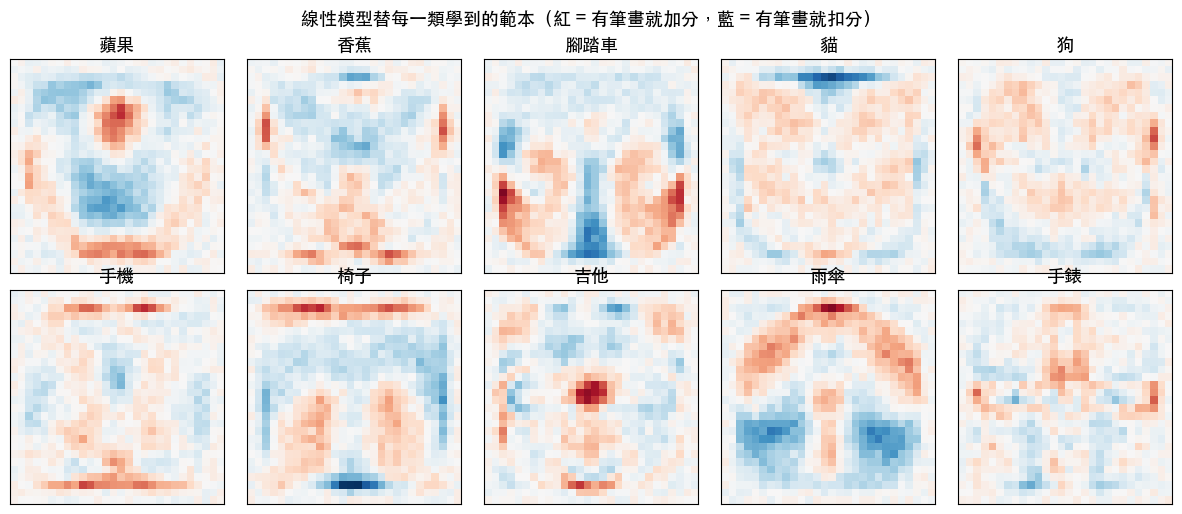

In [11]:
weights = linear[1].weight.detach().cpu().reshape(10, 28, 28)   # (10, 784) → 10 張 28×28
limit = weights.abs().max().item()                              # 讓紅藍兩邊的顏色深淺對稱

fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
for i, ax in enumerate(axes.flat):
    ax.imshow(weights[i], cmap="RdBu_r", vmin=-limit, vmax=limit)
    ax.set_title(CATEGORIES_ZH[i], fontsize=13)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("線性模型替每一類學到的範本（紅 = 有筆畫就加分，藍 = 有筆畫就扣分）", fontsize=13)
plt.tight_layout()
plt.show()

仔細看會發現模型真的學到了每一類的「長相」：

- **腳踏車**：左右兩邊各有一團紅色，就是**兩個輪子**的位置；中間下方是藍色（輪子之間通常是空的）。
- **雨傘**：上面一道紅色的**拱形**是傘面，中間一條紅線是傘柄，傘面下方兩側是藍色。
- **椅子**：最上面一條紅色橫線是椅背頂端，下面兩條紅色直線是**椅腳**。
- **蘋果**：最上方中間有一團紅色，那是**蘋果的梗**；底部有一道紅色的弧線。
- **吉他**：正中央一團紅色，是吉他的**音孔**。

再看**貓**和**狗**：兩張範本都很模糊，沒有明顯的形狀。因為貓和狗的畫法太多種了
（整隻、只畫臉、側面、正面），平均起來就糊成一片。

**這也正是線性模型的極限**：每一類只能有**一張**範本。
但真實的貓有人畫整隻、有人只畫臉，一張範本不可能同時長得像兩種畫法。

## 8. 第 2 關：加一層隱藏層（MLP，多層感知器）

### 想法

不要讓每一類只有一張範本。改成先準備 **256 個「小偵測器」**，每一個負責找一種特徵
（例如「中間有一個圓」、「上面有一根棒子」、「下面有兩個輪子」），
再根據這 256 個偵測器的結果，決定是哪一類。

```
784 個像素 ──Linear──▶ 256 個偵測器 ──ReLU──▶ ──Linear──▶ 10 個類別的分數
```

### 為什麼中間一定要有 ReLU？

`ReLU(x) = max(0, x)`：負的變成 0，正的保持不變。

如果拿掉 ReLU，兩層 Linear 疊起來，數學上**等於一層 Linear**（兩個矩陣相乘還是一個矩陣），
加了等於沒加。ReLU 讓偵測器變成「有找到才出聲，沒找到就安靜」，網路才真的變聰明。

參數數量：784 × 256 + 256 + 256 × 10 + 10 = **203,530 個**，大約是線性模型的 26 倍。

第  1 輪 | 訓練 loss 1.0618  準確率 68.30% | 驗證 loss 0.7657  準確率 77.02%


第  2 輪 | 訓練 loss 0.7143  準確率 79.05% | 驗證 loss 0.6436  準確率 81.45%


第  3 輪 | 訓練 loss 0.6214  準確率 82.09% | 驗證 loss 0.5888  準確率 83.05%


第  4 輪 | 訓練 loss 0.5708  準確率 83.59% | 驗證 loss 0.5525  準確率 84.35%


第  5 輪 | 訓練 loss 0.5358  準確率 84.52% | 驗證 loss 0.5220  準確率 84.83%
→ 第 2 關 MLP：參數 203,530 個，花了 3.1 秒


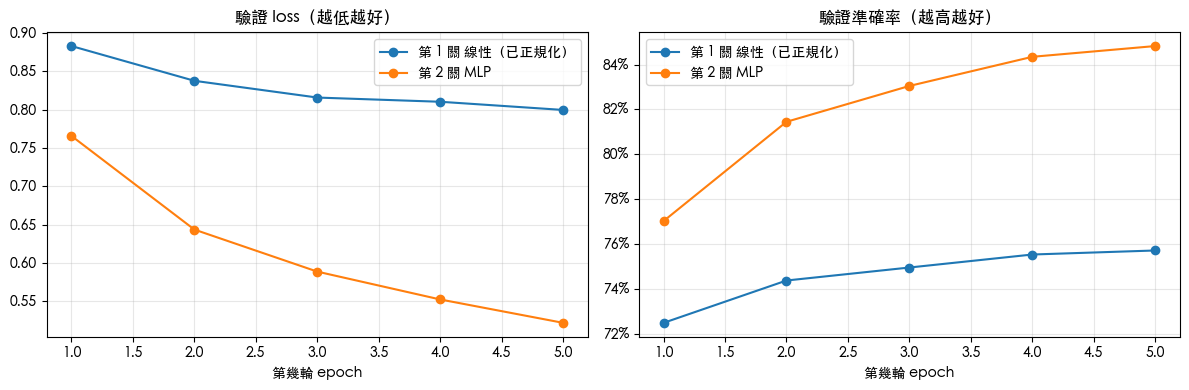

In [12]:
torch.manual_seed(SEED)
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256),   # 第一層：784 → 256 個偵測器
    nn.ReLU(),             # 非線性：沒找到的偵測器輸出 0
    nn.Linear(256, 10),    # 第二層：256 → 10 個類別
)
optimizer = torch.optim.SGD(mlp.parameters(), lr=0.1)
fit("第 2 關 MLP", mlp, optimizer, epochs=5,
    train_loader=train_loader, val_loader=val_loader)
plot_history("第 1 關 線性（已正規化）", "第 2 關 MLP")

加了一層隱藏層，驗證 loss 從 0.80 降到 **0.52**，準確率從 75.7% 升到 **84.8%**。

注意右邊的曲線：到第 5 輪時還在往上爬，代表 MLP 其實還沒學完，多訓練幾輪還會再好一點。
但我們接下來要換一個**更適合圖片**的架構，效果會好得多。

## 9. 第 3 關：卷積神經網路（CNN）

### MLP 的盲點

MLP 第一步就把圖**攤平成 784 個數字的一長條**。對它來說，第 100 號像素和第 101 號像素是不是鄰居，
它根本不知道。而且同一個圓圈，畫在左邊和畫在右邊，對 MLP 來說是**兩個完全不同的東西**，要分開學。

### 卷積的想法：拿一個小印章在圖上滑

**卷積（convolution）** 用一個很小的格子（例如 3 × 3，叫做**卷積核** kernel），
從圖的左上角一格一格滑到右下角，每到一個位置就檢查「這一小塊長得像不像我要找的東西」。

- **只看附近**：3 × 3 的範圍，所以知道誰是鄰居。
- **同一個印章到處用**：在左邊找圓圈的印章，到右邊一樣能找圓圈，不用重學。

先不用訓練，用兩個**手刻的**卷積核示範：一個找「直線」、一個找「橫線」。

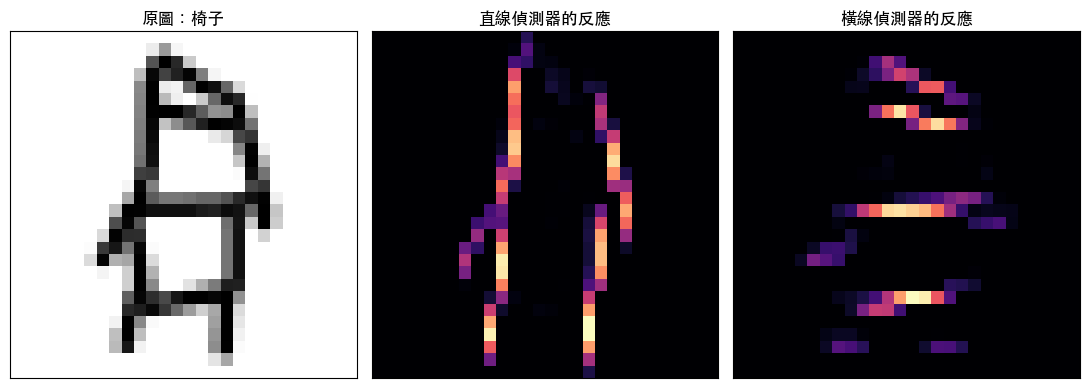

In [13]:
# 兩個手刻的 3×3 卷積核
vertical = torch.tensor([[-1., 2., -1.],
                         [-1., 2., -1.],
                         [-1., 2., -1.]])   # 中間一行比兩旁亮 → 直的筆畫
horizontal = vertical.T.clone()           # 轉置 → 橫的筆畫

pic = x_train[N_TRAIN * CATEGORIES.index("chair")].float() / 255   # 拿一張椅子，形狀 (1, 28, 28)
kernels = torch.stack([vertical, horizontal]).unsqueeze(1)          # 形狀 (2, 1, 3, 3)
maps = F.conv2d(pic.unsqueeze(0), kernels, padding=1)[0]            # 結果形狀 (2, 28, 28)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
axes[0].imshow(pic[0], cmap="gray_r")
axes[0].set_title("原圖：椅子")
axes[1].imshow(maps[0].clamp(min=0), cmap="magma")
axes[1].set_title("直線偵測器的反應")
axes[2].imshow(maps[1].clamp(min=0), cmap="magma")
axes[2].set_title("橫線偵測器的反應")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

亮的地方就是偵測器「有反應」的位置：直線偵測器在椅腳亮起來，橫線偵測器在椅面亮起來。

**CNN 做的事，就是讓模型自己學出這些卷積核**，而不是我們手刻。
第一層學「線條、轉角」這種簡單的東西，後面的層把簡單的組合成「圓圈、輪子、把手」。

### 池化（pooling）：把圖縮小

`MaxPool2d(2)` 把每個 2 × 2 的小方塊只留下最大值，圖的長寬各變成一半。
比喻：從遠一點的地方看圖，細節少了，但「這附近有沒有某個特徵」還留著。

### 我們的第一個 CNN

下面這格會把一張圖丟進去，**印出每一層之後的形狀**，看資料怎麼一路變化。

In [14]:
def make_simple_cnn():
    return nn.Sequential(
        nn.Conv2d(1, 16, kernel_size=3, padding=1),   # 16 個 3×3 卷積核：(1,28,28) → (16,28,28)
        nn.ReLU(),
        nn.MaxPool2d(2),                               # 縮小一半：(16,28,28) → (16,14,14)
        nn.Conv2d(16, 32, kernel_size=3, padding=1),  # 32 個卷積核：→ (32,14,14)
        nn.ReLU(),
        nn.MaxPool2d(2),                               # → (32,7,7)
        nn.Flatten(),                                  # → 32×7×7 = 1568
        nn.Linear(32 * 7 * 7, 128),                    # → 128
        nn.ReLU(),
        nn.Linear(128, 10),                            # → 10 個類別
    )


# 追蹤形狀：一層一層把資料傳下去，順便印出來
probe = torch.zeros(1, 1, 28, 28)
for layer in make_simple_cnn():
    probe = layer(probe)
    print(f"{layer.__class__.__name__:>10s} → {tuple(probe.shape)}")

    Conv2d → (1, 16, 28, 28)
      ReLU → (1, 16, 28, 28)
 MaxPool2d → (1, 16, 14, 14)
    Conv2d → (1, 32, 14, 14)
      ReLU → (1, 32, 14, 14)
 MaxPool2d → (1, 32, 7, 7)
   Flatten → (1, 1568)
    Linear → (1, 128)
      ReLU → (1, 128)
    Linear → (1, 10)


第  1 輪 | 訓練 loss 0.6147  準確率 80.70% | 驗證 loss 0.3152  準確率 90.31%


第  2 輪 | 訓練 loss 0.2974  準確率 90.76% | 驗證 loss 0.2670  準確率 91.68%


第  3 輪 | 訓練 loss 0.2504  準確率 92.08% | 驗證 loss 0.2607  準確率 91.57%


第  4 輪 | 訓練 loss 0.2235  準確率 92.84% | 驗證 loss 0.2571  準確率 92.16%


第  5 輪 | 訓練 loss 0.2021  準確率 93.42% | 驗證 loss 0.2563  準確率 91.91%


第  6 輪 | 訓練 loss 0.1796  準確率 93.97% | 驗證 loss 0.2602  準確率 91.67%


第  7 輪 | 訓練 loss 0.1645  準確率 94.55% | 驗證 loss 0.2602  準確率 91.96%


第  8 輪 | 訓練 loss 0.1469  準確率 95.11% | 驗證 loss 0.2644  準確率 91.94%
→ 第 3 關 CNN：參數 206,922 個，花了 17.7 秒


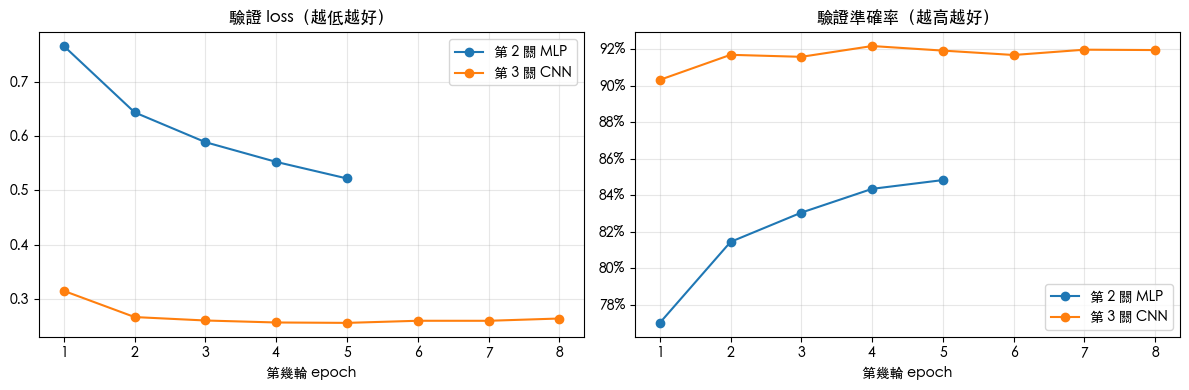

In [15]:
torch.manual_seed(SEED)
cnn = make_simple_cnn()
optimizer = torch.optim.SGD(cnn.parameters(), lr=0.1, momentum=0.9)
fit("第 3 關 CNN", cnn, optimizer, epochs=8,
    train_loader=train_loader, val_loader=val_loader)
plot_history("第 2 關 MLP", "第 3 關 CNN")

驗證 loss 從 MLP 的 0.52 降到 **0.26**（少了一半），準確率從 84.8% 升到 **91.9%**。
而且**第 1 輪結束就已經 90.3%**，比 MLP 訓練 5 輪的最好成績還高。

最值得注意的是參數量：CNN 有 206,922 個，MLP 有 203,530 個，**幾乎一樣多**。
所以進步不是因為模型變大，而是因為**架構更適合圖片**：知道誰是鄰居，同一個偵測器到處都能用。

> 這一關的優化器多加了 `momentum=0.9`（動量）：更新時會帶著上一步的方向，
> 像下坡時的滾球有慣性，不會被每一批資料的小起伏拉來拉去。
> 卷積網路比較深，用動量會穩定很多。

### 注意訓練和驗證的差距

把這一關的「訓練準確率」和「驗證準確率」放在一起看：

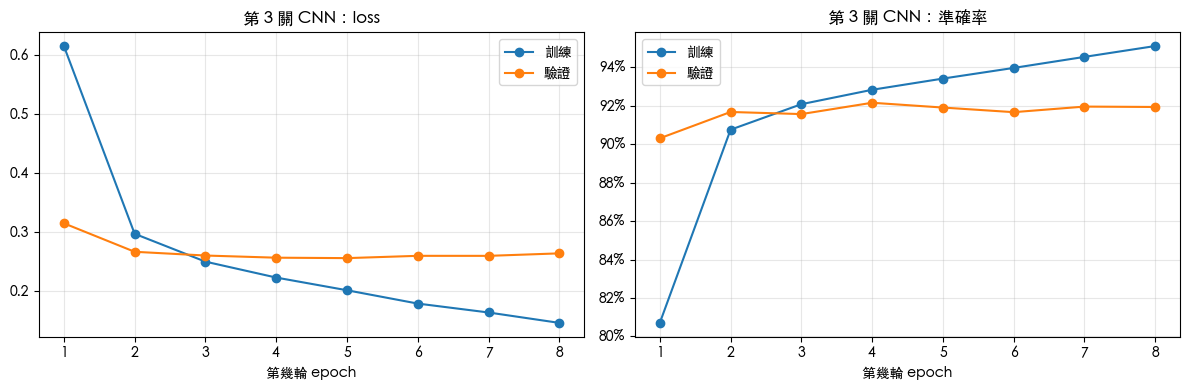

In [16]:
def plot_gap(name):
    '''畫出某一關的訓練 vs 驗證曲線，看兩者差多遠。'''
    h = results[name]["history"]
    epochs = range(1, len(h["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, h["train_loss"], marker="o", label="訓練")
    ax1.plot(epochs, h["val_loss"], marker="o", label="驗證")
    ax2.plot(epochs, h["train_acc"], marker="o", label="訓練")
    ax2.plot(epochs, h["val_acc"], marker="o", label="驗證")
    ax1.set_title(f"{name}：loss")
    ax2.set_title(f"{name}：準確率")
    ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    for ax in (ax1, ax2):
        ax.set_xlabel("第幾輪 epoch")
        ax.grid(alpha=0.3)
        ax.legend()
    plt.tight_layout()
    plt.show()


plot_gap("第 3 關 CNN")

兩條線**分開了**：

| | 第 5 輪 | 第 8 輪 |
|---|---|---|
| 訓練 loss | 0.2021 | 0.1469（還在降） |
| 驗證 loss | **0.2563**（最低點） | 0.2644（開始回升） |
| 訓練準確率 | 93.4% | 95.1% |
| 驗證準確率 | 91.9% | 91.9% |

第 5 輪之後，訓練成績繼續變好，驗證成績卻停住甚至變差。

這就是**過擬合（overfitting）**的開始：模型開始「背」訓練集的答案，
而不是學到能用在新圖上的規律。就像學生把課本習題的答案背起來，模擬考卻沒有進步。
第 5 關會專門處理這件事。

## 10. 第 4 關：更深的 CNN + BatchNorm

### 更深 = 能組合出更複雜的特徵

多加幾層卷積，模型就能把「線條 → 圓圈 → 輪子 → 腳踏車」一層一層組起來。

### 但深的網路不好訓練：BatchNorm 來幫忙

每一層的輸出，數值範圍會隨著訓練一直漂移；下一層每一步都得重新適應，學得很辛苦。

**BatchNorm（批次正規化）** 在每一層之後，把這一批資料的數值**重新調整成平均 0、標準差 1**，
再讓模型自己學要不要放大、平移一點。這跟第 1 關「除以 255」是同一個道理，
只是**每一層都做**，而不是只在輸入做一次。

### 這一關只改架構

優化器、學習率、訓練輪數都跟第 3 關一樣，這樣才知道進步是誰的功勞。

第  1 輪 | 訓練 loss 0.3037  準確率 90.53% | 驗證 loss 0.2251  準確率 92.89%


第  2 輪 | 訓練 loss 0.1840  準確率 94.09% | 驗證 loss 0.1925  準確率 94.15%


第  3 輪 | 訓練 loss 0.1494  準確率 95.06% | 驗證 loss 0.2114  準確率 93.50%


第  4 輪 | 訓練 loss 0.1252  準確率 95.79% | 驗證 loss 0.1869  準確率 93.98%


第  5 輪 | 訓練 loss 0.1032  準確率 96.47% | 驗證 loss 0.2040  準確率 94.05%


第  6 輪 | 訓練 loss 0.0855  準確率 97.06% | 驗證 loss 0.2103  準確率 93.78%


第  7 輪 | 訓練 loss 0.0665  準確率 97.69% | 驗證 loss 0.2251  準確率 93.93%


第  8 輪 | 訓練 loss 0.0525  準確率 98.17% | 驗證 loss 0.2509  準確率 93.62%
→ 第 4 關 深 CNN + BatchNorm：參數 437,418 個，花了 81.0 秒


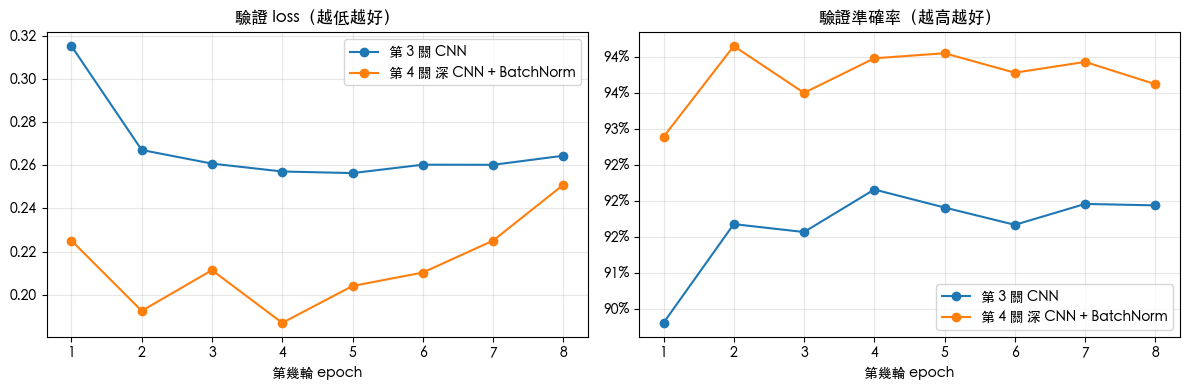

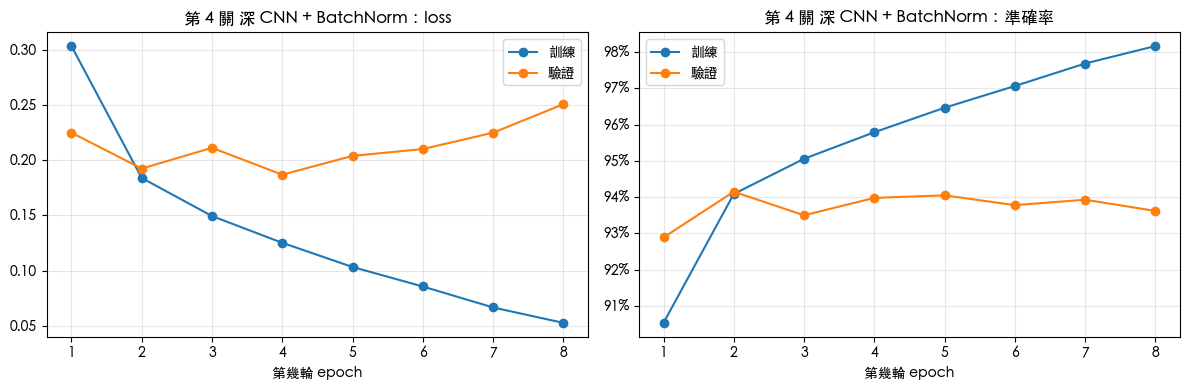

In [17]:
def conv_block(c_in, c_out):
    '''卷積 → BatchNorm → ReLU，這三個常常綁在一起用。'''
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, kernel_size=3, padding=1, bias=False),  # 後面有 BatchNorm，偏置是多餘的
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
    )


def make_deep_cnn(dropout=0.0):
    return nn.Sequential(
        conv_block(1, 32), conv_block(32, 32), nn.MaxPool2d(2),     # (32, 14, 14)
        conv_block(32, 64), conv_block(64, 64), nn.MaxPool2d(2),    # (64, 7, 7)
        conv_block(64, 128), nn.MaxPool2d(2),                       # (128, 3, 3)
        nn.Flatten(),                                               # 128 × 3 × 3 = 1152
        nn.Dropout(dropout),        # 第 5 關才會把 dropout 設成大於 0
        nn.Linear(128 * 3 * 3, 256),
        nn.BatchNorm1d(256),
        nn.ReLU(),
        nn.Dropout(dropout),
        nn.Linear(256, 10),
    )


torch.manual_seed(SEED)
deep = make_deep_cnn()
optimizer = torch.optim.SGD(deep.parameters(), lr=0.1, momentum=0.9)
fit("第 4 關 深 CNN + BatchNorm", deep, optimizer, epochs=8,
    train_loader=train_loader, val_loader=val_loader)
plot_history("第 3 關 CNN", "第 4 關 深 CNN + BatchNorm")
plot_gap("第 4 關 深 CNN + BatchNorm")

準確率從 91.9% 升到 **93.6%**，但驗證 loss 只從 0.264 降到 **0.251**，幾乎沒動。為什麼？

看下面那張訓練 vs 驗證的圖就知道：**過擬合變得更嚴重了。**

| | 訓練 | 驗證 |
|---|---|---|
| 第 8 輪準確率 | **98.2%** | 93.6% |
| 驗證 loss 最低點 | — | **0.1869**（第 4 輪） |
| 第 8 輪驗證 loss | — | 0.2509（回升了） |

更深的模型（437,418 個參數，是第 3 關的兩倍）有能力把訓練集背得更熟，
所以第 4 輪之後就開始「背答案」。背答案會讓它對自己猜錯的題目也**非常有把握**，
loss 因此被拉高，雖然猜對的題數還是變多了。

所以這一關的結論是：**模型的能力夠了，問題變成它太會背。** 下一關就來處理這件事。

另外，深的模型也比較慢：每輪大約 10 秒，第 3 關只要 2 秒左右。

## 11. 第 5 關：對抗過擬合——Dropout 與資料增強

### 方法一：Dropout

訓練時，**每一批都隨機關掉一部分神經元**（這裡關掉 30%），被關掉的那次就當它不存在。

比喻：一個團隊如果每次開會都會隨機有人請假，大家就不能只依賴某一個人，
每個人都得學會一點別人的工作，團隊整體變得比較可靠。
**只有訓練時會關，評估時全員到齊**（`model.train()` / `model.eval()` 就是在切換這件事）。

### 方法二：資料增強（data augmentation）

把訓練圖**隨機旋轉一點、平移一點、縮放一點**，但答案不變。
一顆稍微歪掉的蘋果還是蘋果。

這等於免費多出很多「新的」練習題，模型就沒辦法只靠背答案過關。
而且玩家在遊戲裡畫的圖，位置和大小一定不會跟資料集一模一樣，這也剛好讓模型提早適應。

先看看增強後的圖長什麼樣子：

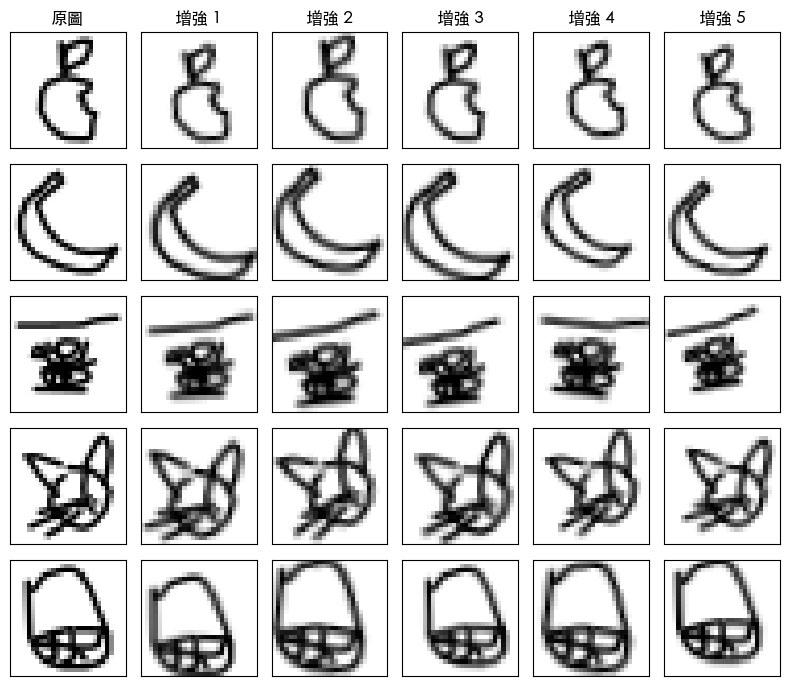

In [18]:
def random_affine(x, max_degrees=12, max_shift=0.08, scale_range=(0.9, 1.1)):
    '''對一批圖各自隨機做旋轉、平移、縮放。x 的形狀是 (批次, 1, 28, 28)。

    做法：替每張圖產生一個 2×3 的「仿射矩陣」，再讓 PyTorch 依照矩陣重新取樣像素。
    這些運算全部在 GPU 上一次對整批完成，所以很快。
    '''
    n = x.size(0)
    angle = (torch.rand(n, device=x.device) * 2 - 1) * math.radians(max_degrees)   # 每張圖的旋轉角度
    scale = torch.empty(n, device=x.device).uniform_(*scale_range)                   # 每張圖的縮放倍率
    shift = (torch.rand(n, 2, device=x.device) * 2 - 1) * max_shift * 2              # 座標範圍是 -1~1，所以乘 2

    cos, sin = torch.cos(angle) / scale, torch.sin(angle) / scale
    theta = torch.stack([
        torch.stack([cos, -sin, shift[:, 0]], dim=1),
        torch.stack([sin, cos, shift[:, 1]], dim=1),
    ], dim=1)                                                       # 形狀 (n, 2, 3)
    grid = F.affine_grid(theta, x.shape, align_corners=False)       # 每個輸出像素該去原圖哪裡取值
    return F.grid_sample(x, grid, align_corners=False, padding_mode="zeros")


torch.manual_seed(SEED)
originals = (x_train[[0, 10_000, 20_000, 30_000, 50_000]].float() / 255).to(device)
fig, axes = plt.subplots(5, 6, figsize=(8, 7))
for row in range(5):
    axes[row, 0].imshow(originals[row, 0].cpu(), cmap="gray_r")
    augmented = random_affine(originals[row:row + 1].repeat(5, 1, 1, 1))   # 同一張圖增強 5 次
    for col in range(5):
        axes[row, col + 1].imshow(augmented[col, 0].cpu(), cmap="gray_r")
axes[0, 0].set_title("原圖")
for col in range(1, 6):
    axes[0, col].set_title(f"增強 {col}")
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

每一張都還認得出是同一個東西，但位置、角度、大小都有一點不一樣。

### 這一關：同樣的深 CNN，加上 Dropout 和資料增強

因為題目變難了，模型需要多一點時間學，所以這一關訓練 **12 輪**。
為了公平比較，我們等一下會把這一關第 8 輪的成績也拿出來跟第 4 關比。

第  1 輪 | 訓練 loss 0.4517  準確率 85.75% | 驗證 loss 0.2513  準確率 92.39%


第  2 輪 | 訓練 loss 0.2794  準確率 91.20% | 驗證 loss 0.2292  準確率 93.00%


第  3 輪 | 訓練 loss 0.2450  準確率 92.27% | 驗證 loss 0.1957  準確率 93.85%


第  4 輪 | 訓練 loss 0.2217  準確率 92.88% | 驗證 loss 0.1834  準確率 94.23%


第  5 輪 | 訓練 loss 0.2056  準確率 93.43% | 驗證 loss 0.1670  準確率 94.66%


第  6 輪 | 訓練 loss 0.1992  準確率 93.62% | 驗證 loss 0.1690  準確率 94.59%


... (2 outputs left out)

第  9 輪 | 訓練 loss 0.1774  準確率 94.16% | 驗證 loss 0.1542  準確率 95.00%


第 10 輪 | 訓練 loss 0.1717  準確率 94.38% | 驗證 loss 0.1658  準確率 94.69%


第 11 輪 | 訓練 loss 0.1652  準確率 94.61% | 驗證 loss 0.1457  準確率 95.24%


第 12 輪 | 訓練 loss 0.1625  準確率 94.62% | 驗證 loss 0.1455  準確率 95.16%
→ 第 5 關 + Dropout + 資料增強：參數 437,418 個，花了 124.7 秒

第 8 輪比較：第 4 關驗證 loss 0.2509，第 5 關驗證 loss 0.1579


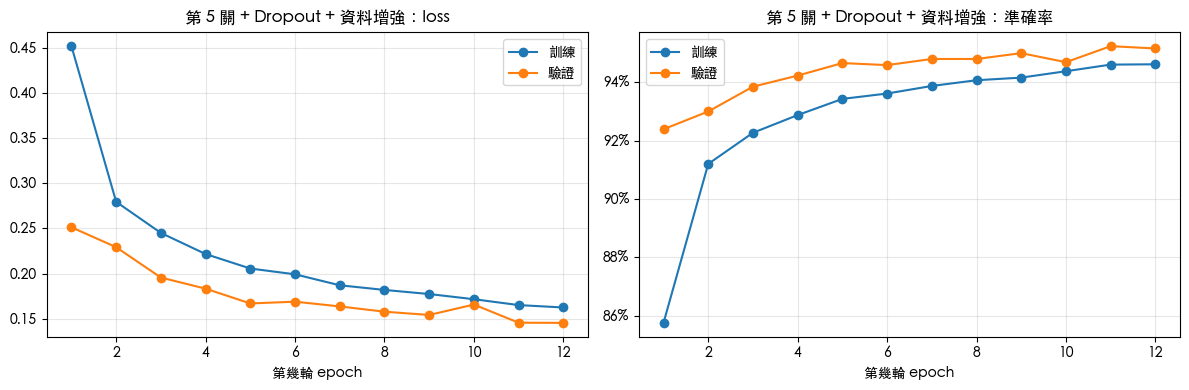

In [19]:
torch.manual_seed(SEED)
regularized = make_deep_cnn(dropout=0.3)
optimizer = torch.optim.SGD(regularized.parameters(), lr=0.1, momentum=0.9)
fit("第 5 關 + Dropout + 資料增強", regularized, optimizer, epochs=12,
    train_loader=train_loader, val_loader=val_loader, augment=random_affine)

h4 = results["第 4 關 深 CNN + BatchNorm"]["history"]
h5 = results["第 5 關 + Dropout + 資料增強"]["history"]
print(f"\n第 8 輪比較：第 4 關驗證 loss {h4['val_loss'][7]:.4f}，第 5 關驗證 loss {h5['val_loss'][7]:.4f}")
plot_gap("第 5 關 + Dropout + 資料增強")

這一關是**降最多的一步之一**：

| | 第 4 關 | 第 5 關 |
|---|---|---|
| 第 8 輪驗證 loss | 0.2509 | **0.1579** |
| 最後驗證 loss | 0.2509（8 輪） | **0.1455**（12 輪） |
| 最後驗證準確率 | 93.6% | **95.2%** |

而且驗證 loss 不再回升，12 輪裡大致一路往下。

### 咦，訓練準確率比驗證還低？

第 12 輪：訓練 94.6%，驗證 **95.2%**。這不是 bug，而是預期中的事：

- **訓練時**的題目被旋轉、平移過，比較難；而且有 30% 的神經元被關掉。
- **驗證時**看的是原圖，而且全員到齊。

就像練習時綁著沙袋跑步，比賽時拿掉沙袋，成績當然比練習好。

## 12. 第 6 關：學習率排程——先大步走，再小步走

### 學習率太大、太小都不好

- **太大**：一直在谷底附近跳來跳去，停不下來。
- **太小**：每一步都很穩，但要走非常久。

那就**兩個都要**：一開始先慢慢加速（暖身），中間用大步快速往下走，
最後越走越小步，穩穩停在谷底。這叫 **One-Cycle 學習率排程**。

比喻：停車的時候，遠遠的先開快一點，接近車位才慢慢減速對準，而不是全程龜速，也不是全速衝進去。

這一關跟第 5 關**一模一樣**，只多了學習率排程。下面先把學習率會怎麼變化畫出來：

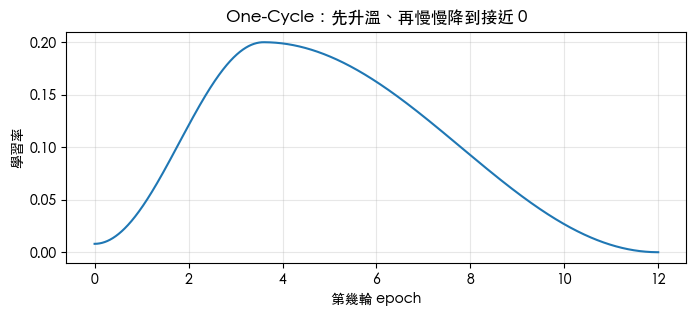

起點 0.0080 → 最高 0.2000 → 終點 0.000001


In [20]:
EPOCHS_6 = 12
steps = EPOCHS_6 * len(train_loader)            # 整個訓練一共會更新幾次

# 建一個假的優化器，只是為了把排程畫出來
dummy = torch.optim.SGD([torch.zeros(1, requires_grad=True)], lr=0.1, momentum=0.9)
preview = torch.optim.lr_scheduler.OneCycleLR(dummy, max_lr=0.2, total_steps=steps)
lrs = []
for _ in range(steps):
    lrs.append(preview.get_last_lr()[0])
    dummy.step()
    preview.step()

plt.figure(figsize=(8, 3))
plt.plot(np.arange(steps) / len(train_loader), lrs)
plt.xlabel("第幾輪 epoch")
plt.ylabel("學習率")
plt.title("One-Cycle：先升溫、再慢慢降到接近 0")
plt.grid(alpha=0.3)
plt.show()
print(f"起點 {lrs[0]:.4f} → 最高 {max(lrs):.4f} → 終點 {lrs[-1]:.6f}")

第  1 輪 | 訓練 loss 0.5550  準確率 82.54% | 驗證 loss 0.2779  準確率 91.51%


第  2 輪 | 訓練 loss 0.3108  準確率 90.27% | 驗證 loss 0.2431  準確率 92.34%


第  3 輪 | 訓練 loss 0.2633  準確率 91.64% | 驗證 loss 0.1947  準確率 93.80%


第  4 輪 | 訓練 loss 0.2325  準確率 92.65% | 驗證 loss 0.2079  準確率 93.67%


第  5 輪 | 訓練 loss 0.2110  準確率 93.23% | 驗證 loss 0.1708  準確率 94.39%


第  6 輪 | 訓練 loss 0.1976  準確率 93.58% | 驗證 loss 0.1801  準確率 94.28%


... (2 outputs left out)

第  9 輪 | 訓練 loss 0.1654  準確率 94.58% | 驗證 loss 0.1492  準確率 95.28%


第 10 輪 | 訓練 loss 0.1532  準確率 94.96% | 驗證 loss 0.1404  準確率 95.56%


第 11 輪 | 訓練 loss 0.1440  準確率 95.20% | 驗證 loss 0.1369  準確率 95.51%


第 12 輪 | 訓練 loss 0.1398  準確率 95.30% | 驗證 loss 0.1362  準確率 95.66%
→ 第 6 關 + 學習率排程：參數 437,418 個，花了 122.2 秒


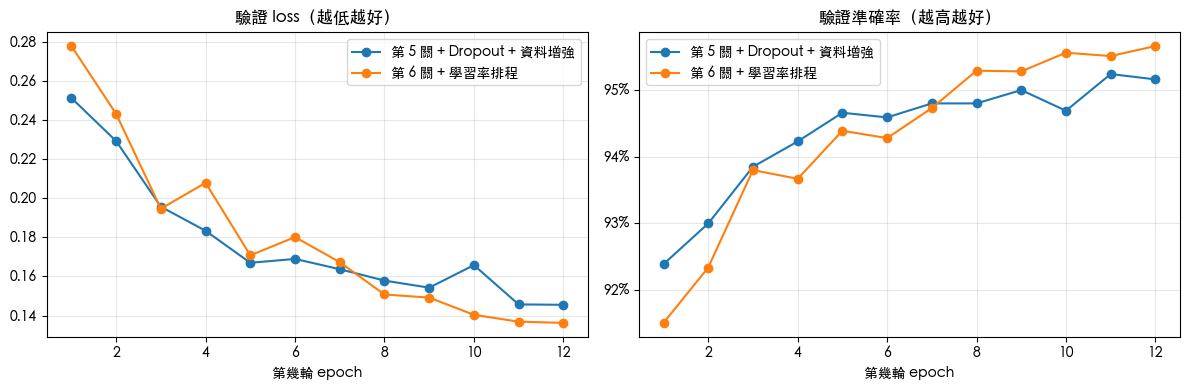

In [21]:
torch.manual_seed(SEED)
final_model = make_deep_cnn(dropout=0.3)
optimizer = torch.optim.SGD(final_model.parameters(), lr=0.1, momentum=0.9)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=0.2, total_steps=steps)
fit("第 6 關 + 學習率排程", final_model, optimizer, epochs=EPOCHS_6,
    train_loader=train_loader, val_loader=val_loader,
    augment=random_affine, scheduler=scheduler)
plot_history("第 5 關 + Dropout + 資料增強", "第 6 關 + 學習率排程")

最後驗證 loss 從 0.1455 降到 **0.1362**，準確率從 95.2% 升到 **95.7%**。

看最後三輪：0.1404 → 0.1369 → 0.1362，越來越平穩。這就是學習率降到接近 0 的效果：
最後幾步走得很小，穩穩停在谷底，不會再被某一批資料拉走。

**誠實說**：這一關進步的幅度（0.5 個百分點）比前面幾關小很多。
我們只用一個隨機種子跑了一次，這麼小的差距有一部分可能是運氣。
要確定排程真的有幫助，正式的做法是換 3–5 個種子各跑一次，比較平均值。

## 13. 成績總表：一路走來 loss 降了多少

,參數量,訓練秒數,驗證 loss,驗證準確率
第 0 關 亂猜,0,0.0,2.3175,8.25%
第 1 關 線性（未正規化）,7850,1.8,6140.5381,57.94%
第 1 關 線性（已正規化）,7850,2.8,0.7995,75.71%
第 2 關 MLP,203530,3.1,0.5220,84.83%
第 3 關 CNN,206922,17.7,0.2644,91.94%
第 4 關 深 CNN + BatchNorm,437418,81.0,0.2509,93.62%
第 5 關 + Dropout + 資料增強,437418,124.7,0.1455,95.16%
第 6 關 + 學習率排程,437418,122.2,0.1362,95.66%


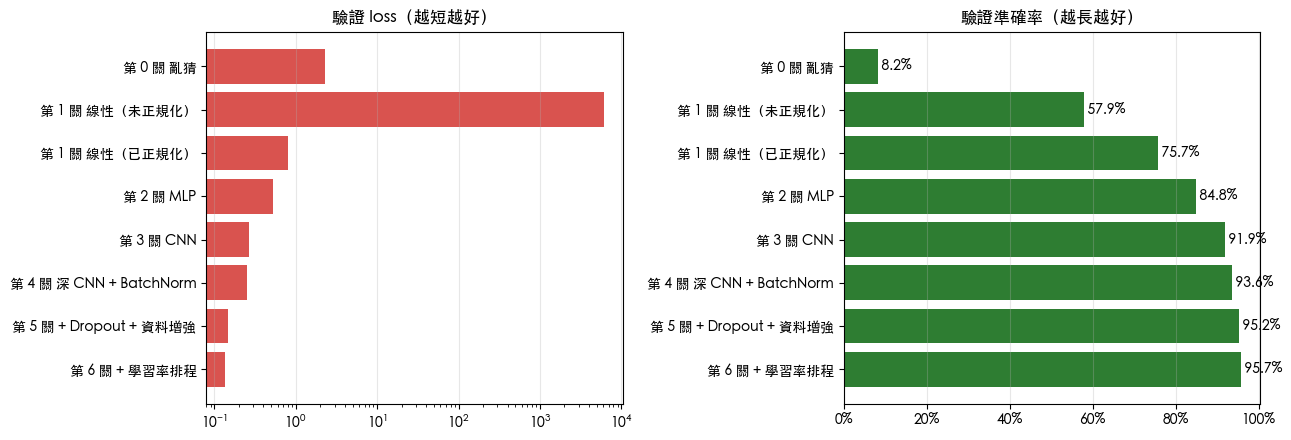

In [22]:
import pandas as pd   # 只用來把成績排成漂亮的表格

names = list(results)
val_losses = [results[n]["val_loss"] for n in names]
val_accs = [results[n]["val_acc"] for n in names]

table = pd.DataFrame({
    "參數量": [results[n]["params"] for n in names],
    "訓練秒數": [round(results[n]["seconds"], 1) for n in names],
    "驗證 loss": [round(v, 4) for v in val_losses],
    "驗證準確率": [f"{v:.2%}" for v in val_accs],
}, index=names)
display(table)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.barh(names, val_losses, color="#d9534f")
ax1.set_title("驗證 loss（越短越好）")
ax1.set_xscale("log")                         # 第 1 關未正規化的 loss 可能非常大，用對數刻度才看得清楚
ax2.barh(names, val_accs, color="#2e7d32")
ax2.set_title("驗證準確率（越長越好）")
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for ax in (ax1, ax2):
    ax.invert_yaxis()
    ax.grid(axis="x", alpha=0.3)
for i, v in enumerate(val_accs):
    ax2.text(v, i, f" {v:.1%}", va="center")
plt.tight_layout()
plt.show()

從頭到尾，驗證 loss 從亂猜的 **2.32** 降到 **0.136**（少了 94%），準確率從 8% 升到 **95.7%**。

降最多的三步是：

| 改了什麼 | 驗證 loss | 學到的事 |
|---|---|---|
| 除以 255（第 1 關） | 6,140 → 0.80 | 輸入的尺度不對，什麼模型都學不好 |
| 換成 CNN（第 3 關） | 0.52 → 0.26 | 參數一樣多，架構對了就差一倍 |
| Dropout + 資料增強（第 5 關） | 0.25 → 0.146 | 模型夠強之後，瓶頸變成「太會背」 |

左邊的 loss 圖用的是**對數刻度**（每一格差 10 倍），不然第 1 關未正規化的 6,140 會把其他長條壓得看不見。

## 14. 期末考：打開測試集

前面所有的選擇（用哪個架構、學習率多少、要不要資料增強）都是看**驗證集**決定的。
現在把最後的模型拿去考**從來沒用過的測試集**，這才是我們可以對外宣稱的成績。

除了一般的準確率，再看一個對遊戲更有意義的指標：**Top-3 準確率**。
遊戲裡會問玩家「這是 ___ 嗎？」，如果第一個猜錯，還可以接著問第二、第三個。

In [23]:
test_loader = DataLoader(TensorDataset(x_test.float() / 255, y_test), batch_size=1024)
final_model.eval()
all_logits, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        all_logits.append(final_model(x.to(device)).cpu())
        all_labels.append(y)
logits = torch.cat(all_logits)
labels = torch.cat(all_labels)

test_loss = F.cross_entropy(logits, labels).item()
preds = logits.argmax(dim=1)
top3 = logits.topk(3, dim=1).indices                       # 每張圖分數最高的 3 類
top1_acc = (preds == labels).float().mean().item()
top3_acc = (top3 == labels[:, None]).any(dim=1).float().mean().item()
print(f"測試集 loss：{test_loss:.4f}")
print(f"Top-1 準確率（第一個就猜對）：{top1_acc:.2%}")
print(f"Top-3 準確率（前三個裡有對的）：{top3_acc:.2%}")
print(f"猜錯的張數：{(preds != labels).sum().item()} / {len(labels)}")

測試集 loss：0.1341
Top-1 準確率（第一個就猜對）：95.59%
Top-3 準確率（前三個裡有對的）：98.95%
猜錯的張數：441 / 10000


測試集的成績：loss **0.134**、Top-1 準確率 **95.6%**，跟驗證集的 0.136 / 95.7% 幾乎一樣。
這是好消息：代表我們前面看驗證集做的那些選擇，並沒有「偷偷針對驗證集」調過頭。

**Top-3 準確率 99.0%**：只要遊戲允許模型猜三次（「是蘋果嗎？不是？那是手錶嗎？」），
一萬張圖裡只有大約 100 張三次都猜不到。

### 混淆矩陣：它最常把什麼搞錯成什麼？

**列**是正確答案，**行**是模型的預測。對角線是猜對的；**對角線以外越深的格子，就是越常搞混的組合。**

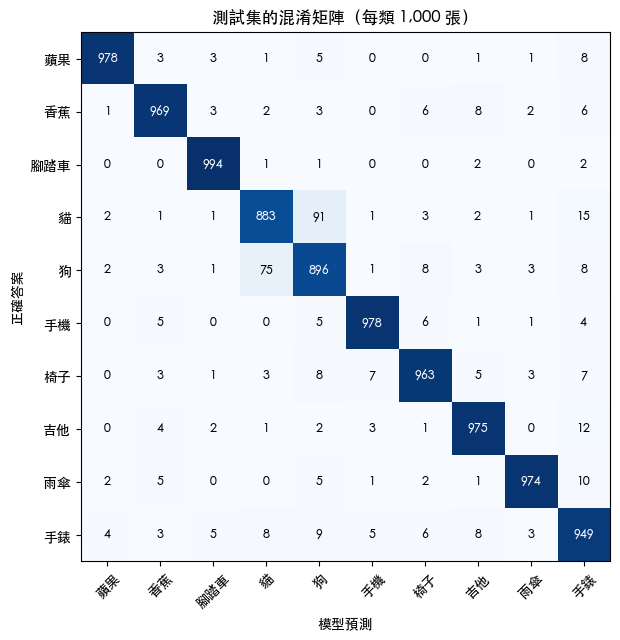

最常搞混的組合：
  正確是「貓」卻猜成「狗」：91 次
  正確是「狗」卻猜成「貓」：75 次
  正確是「貓」卻猜成「手錶」：15 次
  正確是「吉他」卻猜成「手錶」：12 次
  正確是「雨傘」卻猜成「手錶」：10 次


In [24]:
confusion = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(labels, preds):
    confusion[t, p] += 1

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.imshow(confusion, cmap="Blues")
ax.set_xticks(range(10), CATEGORIES_ZH, rotation=45)
ax.set_yticks(range(10), CATEGORIES_ZH)
ax.set_xlabel("模型預測")
ax.set_ylabel("正確答案")
for i in range(10):
    for j in range(10):
        v = confusion[i, j].item()
        ax.text(j, i, v, ha="center", va="center", fontsize=9,
                color="white" if v > confusion.max() / 2 else "black")
ax.set_title("測試集的混淆矩陣（每類 1,000 張）")
plt.tight_layout()
plt.show()

# 找出最常被搞混的前 5 組
off_diag = confusion.clone()
off_diag.fill_diagonal_(0)
values, flat_idx = off_diag.flatten().topk(5)
print("最常搞混的組合：")
for v, idx in zip(values.tolist(), flat_idx.tolist()):
    t, p = divmod(idx, 10)
    print(f"  正確是「{CATEGORIES_ZH[t]}」卻猜成「{CATEGORIES_ZH[p]}」：{v} 次")

不出所料，**貓和狗互相搞混是最大宗**：貓被猜成狗 91 次、狗被猜成貓 75 次，
加起來 166 次，佔全部 441 個錯誤的 **38%**。其他任何一組都在 15 次以下。

這也跟第 7 節線性模型的範本對得起來：那時候貓和狗的範本就是兩團模糊，最難分。

### 看看它猜錯的圖

只看數字不夠，**一定要把猜錯的圖拿出來看**。常常會發現：有些「錯誤」其實是資料本身的問題。

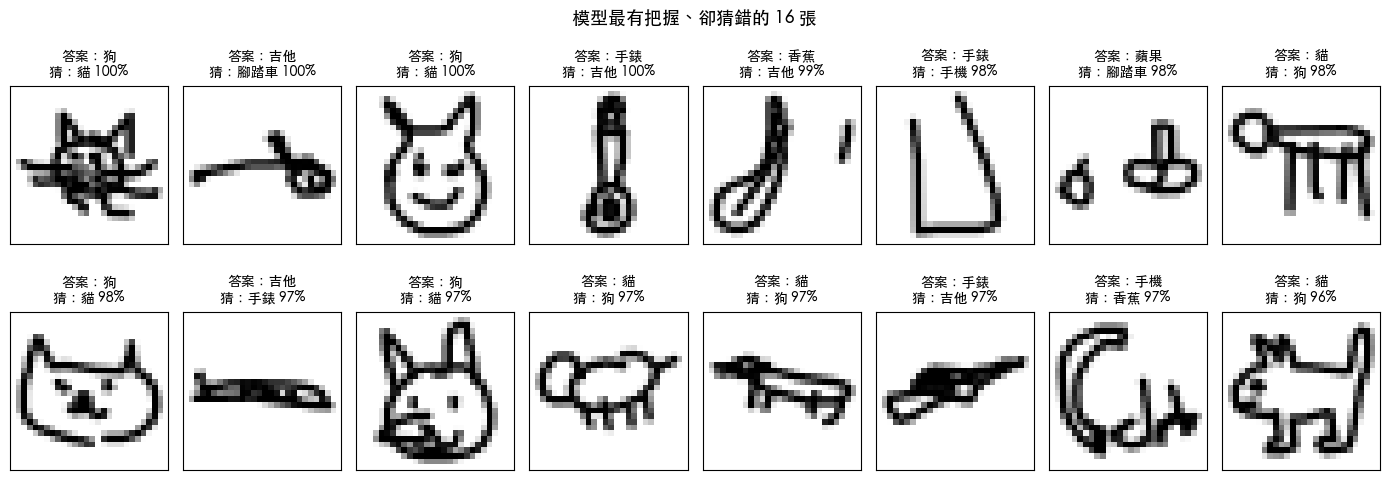

In [25]:
probs = logits.softmax(dim=1)
wrong = (preds != labels).nonzero().flatten()
# 挑「模型很有把握但還是猜錯」的前 16 張，最有參考價值
confidence = probs[wrong, preds[wrong]]
worst = wrong[confidence.argsort(descending=True)[:16]]

fig, axes = plt.subplots(2, 8, figsize=(14, 5.2))
for ax, i in zip(axes.flat, worst.tolist()):
    ax.imshow(x_test[i, 0], cmap="gray_r")
    ax.set_title(f"答案：{CATEGORIES_ZH[labels[i]]}\n猜：{CATEGORIES_ZH[preds[i]]} {probs[i, preds[i]]:.0%}",
                 fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("模型最有把握、卻猜錯的 16 張", fontsize=13)
plt.tight_layout(h_pad=2.0)
plt.show()

仔細看這些「錯誤」，會發現**很多其實不是模型的錯**：

- 好幾張標成「狗」的圖，畫的明明是**尖耳朵加鬍鬚的貓臉**。玩家被要求畫狗，但他畫出來的就是一隻貓。
- 有一張標成「手錶」的圖，看起來比較像溫度計，模型猜吉他。
- 有一張標成「香蕉」的圖，形狀根本是一把吉他。

**模型在這些圖上的判斷，大部分人類也會同意。** 這叫做**標籤雜訊（label noise）**：
資料的答案本身就有錯。所以準確率不可能做到 100%，追求最後那幾個百分點之前，
要先想想剩下的錯誤到底是模型的問題，還是資料的問題。

## 15. 模型看到了什麼？

第 9 節我們手刻了兩個卷積核。現在看看訓練好的模型**第一層自己學出來的 32 個卷積核**，
以及一張圖經過第一層之後，各個卷積核的反應。

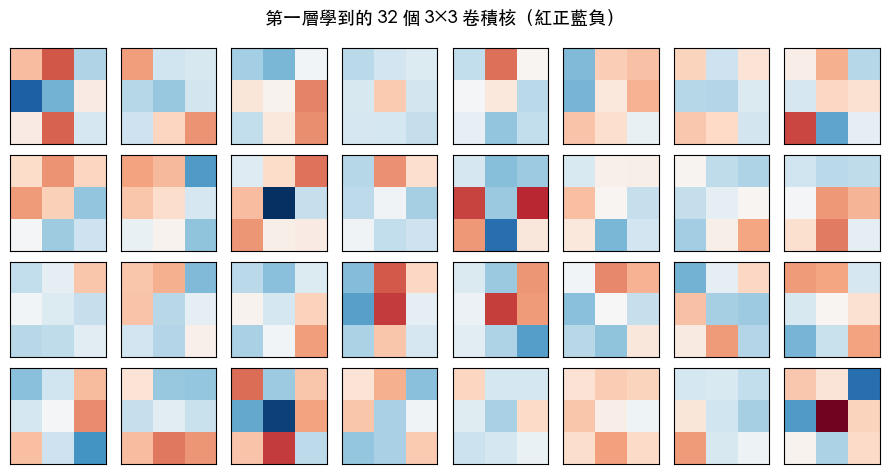

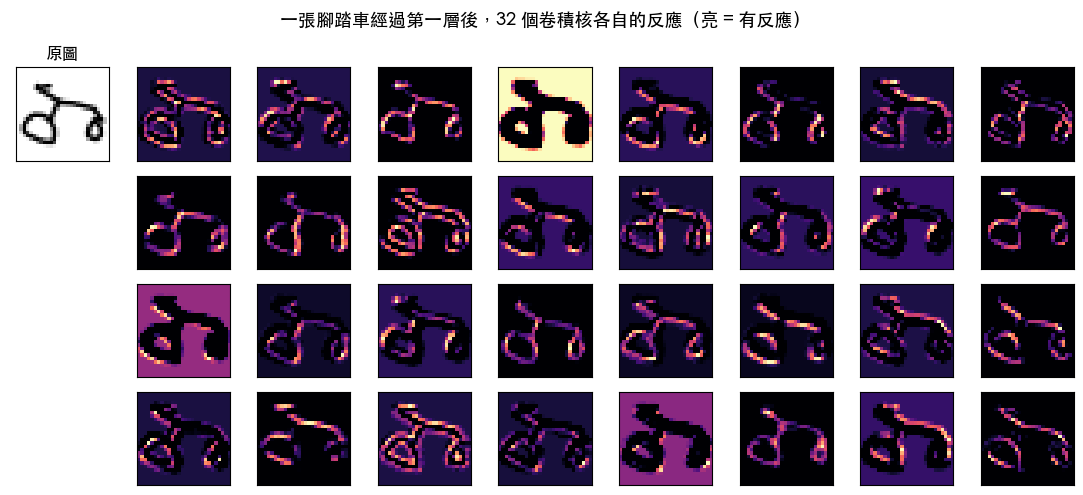

In [26]:
first_conv = final_model[0][0]                        # 第一個 conv_block 裡的 Conv2d
kernels = first_conv.weight.detach().cpu()[:, 0]      # 形狀 (32, 3, 3)

fig, axes = plt.subplots(4, 8, figsize=(9, 4.8))
for k, ax in zip(kernels, axes.flat):
    ax.imshow(k, cmap="RdBu_r", vmin=-kernels.abs().max(), vmax=kernels.abs().max())
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("第一層學到的 32 個 3×3 卷積核（紅正藍負）", fontsize=13)
plt.tight_layout()
plt.show()

# 一張腳踏車經過第一層（卷積 + BatchNorm + ReLU）之後的 32 張反應圖
bike = (x_test[CATEGORIES.index("bicycle") * N_TEST].float() / 255).unsqueeze(0).to(device)
with torch.no_grad():
    activation = final_model[0](bike)[0].cpu()        # 形狀 (32, 28, 28)

fig, axes = plt.subplots(4, 9, figsize=(11, 5))
axes[0, 0].imshow(bike[0, 0].cpu(), cmap="gray_r")
axes[0, 0].set_title("原圖")
for i, ax in enumerate([a for j, a in enumerate(axes.flat) if j % 9 != 0]):
    ax.imshow(activation[i], cmap="magma")
for row in range(1, 4):
    axes[row, 0].axis("off")
for ax in axes.flat:
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("一張腳踏車經過第一層後，32 個卷積核各自的反應（亮 = 有反應）", fontsize=13)
plt.tight_layout()
plt.show()

每個卷積核負責的東西都不一樣：大部分只在**某個方向的筆畫邊緣**亮起來（有的亮在左邊緣，有的亮在上邊緣）；
也有幾個剛好相反，**背景是亮的、筆畫是暗的**，等於在找「哪裡是空白」。
跟第 9 節手刻的直線、橫線偵測器是同一類東西，只是這次是模型自己學出來的。

## 16. 把模型存起來

訓練好的權重要存成檔案，之後遊戲的 Python 服務（`ml/sellanything_ml/server.py`）才能載入來用。

我們存的是 **`state_dict`**：一個「參數名稱 → 數值」的字典，不含程式碼。
載入時要先用同樣的 `make_deep_cnn()` 建出空的模型，再把數值倒進去。

`ml/checkpoints/` 已經在 `.gitignore` 裡，模型檔不會被 commit（太大，之後會放到 Hugging Face）。

In [27]:
CHECKPOINT_DIR = Path("../checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
path = CHECKPOINT_DIR / "sketch_cnn_10class.pt"

torch.save({
    "state_dict": final_model.state_dict(),
    "categories": CATEGORIES,
    "test_top1": top1_acc,
    "test_top3": top3_acc,
}, path)
print(f"已儲存：{path}（{path.stat().st_size / 1024:.0f} KB）")

# 驗證：重新建一個空模型、載入權重，確認預測結果一模一樣
checkpoint = torch.load(path, map_location=device)
reloaded = make_deep_cnn(dropout=0.3).to(device)
reloaded.load_state_dict(checkpoint["state_dict"])
reloaded.eval()
with torch.no_grad():
    sample_batch = (x_test[:256].float() / 255).to(device)
    same = torch.equal(reloaded(sample_batch).argmax(1), final_model(sample_batch).argmax(1))
print("重新載入後預測完全相同：", same)
print(f"整本筆記本跑了 {(time.time() - NOTEBOOK_START) / 60:.1f} 分鐘")

已儲存：../checkpoints/sketch_cnn_10class.pt（1726 KB）
重新載入後預測完全相同： True
整本筆記本跑了 5.9 分鐘


## 17. 下一步

| 下一步 | 為什麼 |
|---|---|
| **把玩家畫的筆畫轉成 28 × 28** | 遊戲送來的是筆畫座標，要用跟 Quick, Draw! 一樣的方法畫成圖（置中、縮放、加粗），模型才看得懂 |
| **擴充到更多類別** | 改 `CATEGORIES` 清單就好；類別變多之後，第 4–6 關的技巧會更重要 |
| **處理「不能賣」的東西** | `items.tsv` 裡有 124 類是 refuse，也要讓模型認得出來，買家 GPT 才能拒絕 |
| **接上遊戲** | 在 `server.py` 的 `classify` 裡載入這個模型 |

### 這本筆記本學到的事

1. **先建立基準線**，才知道進步了多少（第 0 關）。
2. **輸入要正規化**，不然連最簡單的模型都學不起來（第 1 關）。
3. **ReLU 讓多層有意義**，不然疊再多層都等於一層（第 2 關）。
4. **卷積知道誰是鄰居**，而且同一個偵測器到處都能用（第 3 關）。
5. **BatchNorm 讓深的網路好訓練**（第 4 關）。
6. **訓練和驗證的差距就是過擬合**，Dropout 和資料增強可以縮小它（第 5 關）。
7. **學習率不必固定**，先大後小通常更好（第 6 關）。
8. **測試集只在最後用一次**，而且一定要看猜錯的圖（期末考）。